In [1]:
import os
import h5py
import time
import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
from pandas import DataFrame
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os
import h5py
import time
import matplotlib
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns
from pandas import DataFrame
import matplotlib.pyplot as plt
from matplotlib import gridspec
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
%matplotlib inline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from deap import algorithms, base, creator, tools
import tensorflow as tf
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Masking, TimeDistributed
from keras.models import Sequential
from keras.layers import Dense, Conv1D
from keras.layers import Dropout, Input
from keras import initializers
from keras.layers import MaxPooling1D
from keras.models import Model
from keras.layers import TimeDistributed, Flatten
from keras.layers import Dense, Activation, Dropout
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint
%matplotlib inline

In [2]:
filename = 'N-CMAPSS_DS05.h5'

In [3]:
# Time tracking, Operation time (min):  0.003
t = time.process_time()  

# Load data
with h5py.File(filename, 'r') as hdf:
        # Development set
        W_dev = np.array(hdf.get('W_dev'))             # W
        X_s_dev = np.array(hdf.get('X_s_dev'))         # X_s
        X_v_dev = np.array(hdf.get('X_v_dev'))         # X_v
        T_dev = np.array(hdf.get('T_dev'))             # T
        Y_dev = np.array(hdf.get('Y_dev'))             # RUL  
        A_dev = np.array(hdf.get('A_dev'))             # Auxiliary

        # Test set
        W_test = np.array(hdf.get('W_test'))           # W
        X_s_test = np.array(hdf.get('X_s_test'))       # X_s
        X_v_test = np.array(hdf.get('X_v_test'))       # X_v
        T_test = np.array(hdf.get('T_test'))           # T
        Y_test = np.array(hdf.get('Y_test'))           # RUL  
        A_test = np.array(hdf.get('A_test'))           # Auxiliary
        
        # Varnams
        W_var = np.array(hdf.get('W_var'))
        X_s_var = np.array(hdf.get('X_s_var'))  
        X_v_var = np.array(hdf.get('X_v_var')) 
        T_var = np.array(hdf.get('T_var'))
        A_var = np.array(hdf.get('A_var'))
        
        # from np.array to list dtype U4/U5
        W_var = list(np.array(W_var, dtype='U20'))
        X_s_var = list(np.array(X_s_var, dtype='U20'))  
        X_v_var = list(np.array(X_v_var, dtype='U20')) 
        T_var = list(np.array(T_var, dtype='U20'))
        A_var = list(np.array(A_var, dtype='U20'))
                          
W = np.concatenate((W_dev, W_test), axis=0)  
X_s = np.concatenate((X_s_dev, X_s_test), axis=0)
X_v = np.concatenate((X_v_dev, X_v_test), axis=0)
T = np.concatenate((T_dev, T_test), axis=0)
Y = np.concatenate((Y_dev, Y_test), axis=0) 
A = np.concatenate((A_dev, A_test), axis=0) 
    
print('')
print("Operation time (min): " , (time.process_time()-t)/60)
print('')
print ("W shape: " + str(W.shape))
print ("X_s shape: " + str(X_s.shape))
print ("X_v shape: " + str(X_v.shape))
print ("Y shape: " + str(Y.shape))
print ("T shape: " + str(T.shape))
print ("A shape: " + str(A.shape))


Operation time (min):  0.031510416666666666

W shape: (6912652, 4)
X_s shape: (6912652, 14)
X_v shape: (6912652, 14)
Y shape: (6912652, 1)
T shape: (6912652, 10)
A shape: (6912652, 4)


In [4]:
W = np.concatenate((W_dev, W_test), axis=0)  
X_s = np.concatenate((X_s_dev, X_s_test), axis=0)
Y = np.concatenate((Y_dev, Y_test), axis=0)
A = np.concatenate((A_dev, A_test), axis=0) 

X = np.concatenate((W, X_s, A, Y), axis=1)
Y=  np.concatenate((A, Y), axis=1)
Y = DataFrame(data=Y, columns=A_var+['Y'])
X = DataFrame(data=X, columns=W_var+X_s_var+A_var+['Y'])

In [5]:
Y.describe()

,unit,cycle,Fc,hs,Y
count,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06
mean,5.239374e+00,4.002810e+01,2.226115e+00,2.958030e-01,3.900481e+01
std,2.904136e+00,2.368351e+01,8.078304e-01,4.564029e-01,2.376696e+01
min,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,2.000000e+00,2.000000e+01,2.000000e+00,0.000000e+00,1.900000e+01
50%,6.000000e+00,3.900000e+01,2.000000e+00,0.000000e+00,3.800000e+01
75%,8.000000e+00,5.900000e+01,3.000000e+00,1.000000e+00,5.800000e+01
max,1.000000e+01,1.000000e+02,3.000000e+00,1.000000e+00,9.900000e+01


In [6]:
Y.drop("cycle",axis=1,inplace=True)
Y.drop("Fc",axis=1,inplace=True)
Y.drop("hs",axis=1,inplace=True)
Y.describe()

,unit,Y
count,6.912652e+06,6.912652e+06
mean,5.239374e+00,3.900481e+01
std,2.904136e+00,2.376696e+01
min,1.000000e+00,0.000000e+00
25%,2.000000e+00,1.900000e+01
50%,6.000000e+00,3.800000e+01
75%,8.000000e+00,5.800000e+01
max,1.000000e+01,9.900000e+01


In [7]:
X.drop("cycle",axis=1,inplace=True)
X.drop("Fc",axis=1,inplace=True)
X.drop("hs",axis=1,inplace=True)
X.drop("alt",axis=1,inplace=True)
X.describe()

,Mach,TRA,T2,T24,T30,T48,T50,P15,P2,P21,P24,Ps30,P40,P50,Nf,Nc,Wf,unit,Y
count,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06
mean,5.319760e-01,5.996256e+01,4.909356e+02,5.699286e+02,1.334474e+03,1.638378e+03,1.129818e+03,1.304474e+01,1.019378e+01,1.324339e+01,1.606218e+01,2.379398e+02,2.422144e+02,1.019697e+01,1.953364e+03,8.248141e+03,2.548930e+00,5.239374e+00,3.900481e+01
std,1.208898e-01,1.834395e+01,1.985279e+01,2.112542e+01,6.869315e+01,1.239105e+02,6.251462e+01,2.883393e+00,2.421477e+00,2.927303e+00,3.450926e+00,5.919650e+01,6.003612e+01,2.758136e+00,1.873247e+02,2.277543e+02,7.877672e-01,2.904136e+00,2.376696e+01
min,3.150000e-04,2.355452e+01,4.369255e+02,4.998511e+02,1.091806e+03,1.095354e+03,7.923581e+02,6.700688e+00,5.285918e+00,6.802729e+00,8.186232e+00,9.248497e+01,9.466065e+01,4.635623e+00,1.471000e+03,7.429764e+03,5.963687e-01,1.000000e+00,0.000000e+00
25%,4.393620e-01,4.631803e+01,4.741667e+02,5.546204e+02,1.287931e+03,1.552724e+03,1.085702e+03,1.049740e+01,7.972020e+00,1.065726e+01,1.319101e+01,1.929589e+02,1.965787e+02,7.665725e+00,1.835894e+03,8.094517e+03,1.980253e+00,2.000000e+00,1.900000e+01
50%,5.371380e-01,6.257768e+01,4.960515e+02,5.678197e+02,1.329839e+03,1.647608e+03,1.120127e+03,1.338949e+01,1.060965e+01,1.359339e+01,1.617596e+01,2.256779e+02,2.301263e+02,1.051082e+01,1.997333e+03,8.237001e+03,2.340848e+00,6.000000e+00,3.800000e+01
75%,6.330240e-01,7.664008e+01,5.072438e+02,5.838195e+02,1.373982e+03,1.711727e+03,1.165307e+03,1.528072e+01,1.209400e+01,1.551342e+01,1.847904e+01,2.724938e+02,2.773639e+02,1.232305e+01,2.112084e+03,8.383625e+03,2.948869e+00,8.000000e+00,5.800000e+01
max,7.492590e-01,8.876890e+01,5.343834e+02,6.341967e+02,1.540888e+03,1.993206e+03,1.356282e+03,2.044899e+01,1.568410e+01,2.076040e+01,2.643985e+01,4.485121e+02,4.553945e+02,1.672457e+01,2.285550e+03,8.921408e+03,5.607345e+00,1.000000e+01,9.900000e+01


In [8]:
df_A = DataFrame(data=A, columns=A_var)
df_A.describe()

,unit,cycle,Fc,hs
count,6.912652e+06,6.912652e+06,6.912652e+06,6.912652e+06
mean,5.239374e+00,4.002810e+01,2.226115e+00,2.958030e-01
std,2.904136e+00,2.368351e+01,8.078304e-01,4.564029e-01
min,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
25%,2.000000e+00,2.000000e+01,2.000000e+00,0.000000e+00
50%,6.000000e+00,3.900000e+01,2.000000e+00,0.000000e+00
75%,8.000000e+00,5.900000e+01,3.000000e+00,1.000000e+00
max,1.000000e+01,1.000000e+02,3.000000e+00,1.000000e+00


In [9]:
print('Engine units in df: ', np.unique(X['unit']))
print('Engine units in df: ', np.unique(Y['unit']))


Engine units in df:  [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
Engine units in df:  [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]


In [9]:
X_train= X.loc[(X.unit == 1) | (X.unit == 3) | (X.unit == 5) | (X.unit == 6) | (X.unit == 7) | (X.unit == 9) | (X.unit == 10) ]
Y_train=Y.loc[(Y.unit == 1) | (Y.unit == 3) | (Y.unit == 5) |  (Y.unit == 6) | (Y.unit == 7) | (Y.unit == 9) | (Y.unit == 10) ]
X_test=X.loc[(X.unit == 2) | (X.unit == 4) | (X.unit == 8) ]
Y_test=Y.loc[(Y.unit == 2) | (Y.unit == 4) | (Y.unit == 8) ]

In [11]:
print('Engine units in df: ', np.unique(X_train['unit']))
print('Engine units in df: ', np.unique(Y_train['unit']))
print('Engine units in df: ', np.unique(X_test['unit']))
print('Engine units in df: ', np.unique(Y_test['unit']))
print("X_train size is ",X_train.shape)
print("X_test size is ",X_test.shape)
print("y_train size is ",Y_train.shape)
print("y_test size is ",Y_test.shape)


Engine units in df:  [ 1.  3.  5.  6.  7.  9. 10.]
Engine units in df:  [ 1.  3.  5.  6.  7.  9. 10.]
Engine units in df:  [2. 4. 8.]
Engine units in df:  [2. 4. 8.]
X_train size is  (4900033, 19)
X_test size is  (2012619, 19)
y_train size is  (4900033, 2)
y_test size is  (2012619, 2)


In [10]:
X_train.drop("unit",axis=1,inplace=True)
X_test.drop("unit",axis=1,inplace=True)
X_train.drop("Y",axis=1,inplace=True)
X_test.drop("Y",axis=1,inplace=True)
Y_train.drop("unit",axis=1,inplace=True)
Y_test.drop("unit",axis=1,inplace=True)
print("X_train size is ",X_train.shape)
print("X_test size is ",X_test.shape)
print("y_train size is ",Y_train.shape)
print("y_test size is ",Y_test.shape)

X_train size is  (4900033, 17)
X_test size is  (2012619, 17)
y_train size is  (4900033, 1)
y_test size is  (2012619, 1)


C:\Users\Kamal\AppData\Local\Temp\ipykernel_53284\816249269.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train.drop("unit",axis=1,inplace=True)
C:\Users\Kamal\AppData\Local\Temp\ipykernel_53284\816249269.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test.drop("unit",axis=1,inplace=True)
C:\Users\Kamal\AppData\Local\Temp\ipykernel_53284\816249269.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train.drop("Y",axis=

In [24]:
def reshape_time_series(data, sequence_length):
    """
    Reshapes time series data for CNN input.

    Parameters:
    data (np.array): The time series dataset, expected to be a 2D array.
    sequence_length (int): The length of the input sequences for the CNN.

    Returns:
    np.array: Reshaped dataset suitable for CNN input.
    """
    X = []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i + sequence_length])

    return np.array(X)


In [14]:
X_train = reshape_time_series(X_train,20)
X_test = reshape_time_series(X_test,20)
Y_train = reshape_time_series(Y_train,20)
Y_test = reshape_time_series(Y_test,20)

In [15]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D
from keras.layers import LSTM
from keras.layers import Dense, Dropout, Flatten

In [16]:
print("X_train size is ",X_train.shape)
print("X_test size is ",X_test.shape)
print("y_train size is ",Y_train.shape)
print("y_test size is ",Y_test.shape)

X_train size is  (4900013, 20, 17)
X_test size is  (2012599, 20, 17)
y_train size is  (4900013, 20, 1)
y_test size is  (2012599, 20, 1)


In [17]:
from sklearn.model_selection import train_test_split

def split_dataset(X, y, train_size=0.8):
    """
    Splits the dataset into training and validation sets.

    Parameters:
    X (np.array): Features of the dataset.
    y (np.array): Labels or targets of the dataset.
    train_size (float): Proportion of the dataset to include in the training set.

    Returns:
    X_train, X_val, y_train, y_val: Split dataset into training and validation sets.
    """
    X_train, X_val, y_train, y_val = train_test_split(X, y, train_size=train_size, random_state=42)
    return X_train, X_val, y_train, y_val

In [18]:
X_train, X_val, Y_train, Y_val = split_dataset(X_train, Y_train, train_size=0.8)


In [19]:
print("X_train shape:", X_train.shape)
print("y_train shape:", Y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", Y_val.shape)

X_train shape: (3920010, 20, 17)
y_train shape: (3920010, 20, 1)
X_val shape: (980003, 20, 17)
y_val shape: (980003, 20, 1)


In [20]:
def reshape_labels_for_regression(y_data):
    """
    Reshapes the labels for a regression task.

    Parameters:
    y_data (np.array): Original labels with shape (number_of_samples, 20, 10).

    Returns:
    np.array: Reshaped labels with shape (number_of_samples, 1).
    """
    # Assuming we want to predict the first value at the last time step of each sequence
    # Adjust the index '0' if a different value is desired
    y_reshaped = y_data[:, -1, 0]  # Select the last time step, first value
    return y_reshaped.reshape(-1, 1)

In [21]:

pip install keras-tuner


Note: you may need to restart the kernel to use updated packages.


In [15]:
from keras.models import Model
from keras.layers import TimeDistributed, Flatten
from sklearn.model_selection import GroupShuffleSplit
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, Dropout, MaxPooling1D, TimeDistributed, Flatten, LSTM, Dense, Masking, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam, RMSprop
from kerastuner.tuners import RandomSearch
from kerastuner.engine.hyperparameters import HyperParameters

C:\Users\Kamal\AppData\Local\Temp\ipykernel_53284\1831089939.py:9: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch


In [23]:
gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs Available: ", len(gpus))
for gpu in gpus:
    print("Name:", gpu.name, "  Type:", gpu.device_type)

Num GPUs Available:  0


In [24]:
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        # Currently, memory growth needs to be the same across GPUs
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.experimental.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        # Memory growth must be set before GPUs have been initialized
        print(e)


In [25]:
sequence_length = 20
num_features =  17
# Define input branches
input_cnn = Input(shape=(sequence_length, num_features))
input_lstm = Input(shape=(sequence_length, num_features))

cnn_branch = Masking(mask_value=-99.)(input_cnn)
cnn_branch = Conv1D(128, kernel_size=3, padding="same", activation="relu")(cnn_branch)
cnn_branch = MaxPooling1D(pool_size=2, padding='same')(cnn_branch)
cnn_branch = Flatten()(cnn_branch)

# LSTM branch
lstm_branch = Masking(mask_value=-99.)(input_lstm)
lstm_branch = LSTM(units=128, return_sequences=False, activation='tanh')(lstm_branch)

# Concatenate the outputs of the two branches
merged = Concatenate()([cnn_branch, lstm_branch])

# Neural Network layer
merged = Dense(200, activation='relu')(merged)
merged = Dropout(0.2)(merged)
output = Dense(1, activation='linear')(merged)

# Create the model
model = Model(inputs=[input_cnn, input_lstm], outputs=output)

# Compile the model
model.compile(loss='mean_squared_error', optimizer='adam')

# Save initial weights
model.save_weights('simple_lstm_weights.h5')

# Set up callbacks
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)
mc = ModelCheckpoint('best_model.h5', monitor='val_loss', mode='max', verbose=1, save_best_only=True)

# Train the model
history = model.fit([X_train, X_train], Y_train,  # Provide the same data for both branches
                    validation_data=([X_val, X_val], Y_val),  # Provide the same data for both branches
                    epochs=20,
                    batch_size=32,
                    callbacks=[es, mc])

Epoch 1/20
122499/122501 [============================>.] - ETA: 0s - loss: 616.8472
Epoch 1: val_loss improved from -inf to 289.16364, saving model to best_model.h5
122501/122501 [==============================] - 1785s 15ms/step - loss: 616.8435 - val_loss: 289.1636
Epoch 2/20


c:\Users\Kamal\anaconda3\envs\myenv\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


122501/122501 [==============================] - ETA: 0s - loss: 305.2814
Epoch 2: val_loss did not improve from 289.16364
122501/122501 [==============================] - 1731s 14ms/step - loss: 305.2814 - val_loss: 249.2055
Epoch 3/20
122499/122501 [============================>.] - ETA: 0s - loss: 275.4724
Epoch 3: val_loss did not improve from 289.16364
122501/122501 [==============================] - 1713s 14ms/step - loss: 275.4725 - val_loss: 219.4031
Epoch 4/20
122498/122501 [============================>.] - ETA: 0s - loss: 257.7774
Epoch 4: val_loss improved from 289.16364 to 292.53906, saving model to best_model.h5
122501/122501 [==============================] - 1801s 15ms/step - loss: 257.7787 - val_loss: 292.5391
Epoch 5/20
122497/122501 [============================>.] - ETA: 0s - loss: 245.8816
Epoch 5: val_loss did not improve from 292.53906
122501/122501 [==============================] - 1966s 16ms/step - loss: 245.8804 - val_loss: 235.5360
Epoch 6/20
122501/122501 [

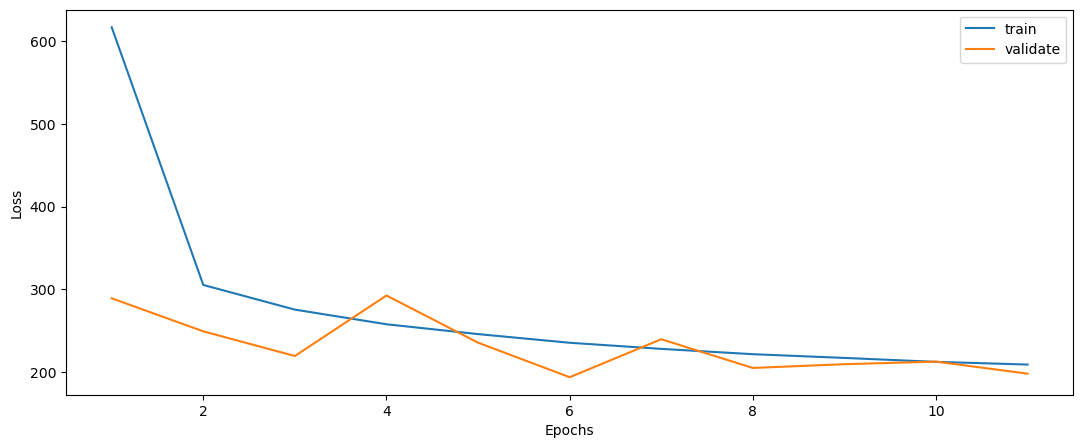

In [26]:
def plot_loss(fit_history):
    plt.figure(figsize=(13,5))
    plt.plot(range(1, len(fit_history.history['loss'])+1), fit_history.history['loss'], label='train')
    plt.plot(range(1, len(fit_history.history['val_loss'])+1), fit_history.history['val_loss'], label='validate')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_loss(history)

In [28]:
def evaluate(y_true, y_hat, label='test'):
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    variance = r2_score(y_true, y_hat)
    print('{} set RMSE:{}, R2:{}'.format(label, rmse, variance))

In [19]:
print (Y_test.shape)
print (X_test.shape)


(2012619, 1)
(2012619, 17)


In [37]:
model.save_weights('model_weights.h5')

In [38]:
del model
from tensorflow.keras.backend import clear_session
clear_session()

In [16]:
def create_model():
    input_cnn = Input(shape=(sequence_length, num_features))
    input_lstm = Input(shape=(sequence_length, num_features))

    cnn_branch = Masking(mask_value=-99.)(input_cnn)
    cnn_branch = Conv1D(128, kernel_size=3, padding="same", activation="relu")(cnn_branch)
    cnn_branch = MaxPooling1D(pool_size=2, padding='same')(cnn_branch)
    cnn_branch = Flatten()(cnn_branch)

    # LSTM branch
    lstm_branch = Masking(mask_value=-99.)(input_lstm)
    lstm_branch = LSTM(units=128, return_sequences=False, activation='tanh')(lstm_branch)

    # Concatenate the outputs of the two branches
    merged = Concatenate()([cnn_branch, lstm_branch])

    # Neural Network layer
    merged = Dense(200, activation='relu')(merged)
    merged = Dropout(0.2)(merged)
    output = Dense(1, activation='linear')(merged)

    # Create the model
    model = Model(inputs=[input_cnn, input_lstm], outputs=output)

    return model

# Compile the model


In [13]:
sequence_length = 20
num_features =  17

In [17]:
model = create_model()
model.load_weights('model_weights.h5')
model.compile(loss='mean_squared_error', optimizer='adam')

In [23]:
import gc

del X_train,Y_train
del X_val,Y_val

NameError: name 'X_val' is not defined

In [25]:
X_test = reshape_time_series(X_test,20)
Y_test = reshape_time_series(Y_test,20)

In [26]:
y_hat_test = model.predict([X_test,X_test])
print (y_hat_test)


62894/62894 [==============================] - 270s 4ms/step
[[62.208702]
 [62.19293 ]
 [62.190807]
 ...
 [ 4.23254 ]
 [ 4.23254 ]
 [ 4.23254 ]]


In [27]:
reshaped_data = Y_test[:, 0, 0]
reshaped_data = reshaped_data[:, np.newaxis]
print(reshaped_data.shape)

(2012599, 1)


In [29]:
evaluate(reshaped_data, y_hat_test)

test set RMSE:13.791271096243166, R2:0.7032116379392457
